<a href="https://colab.research.google.com/github/sidd2307/llm_transformers_working/blob/main/Attention_Is_All_You_Need_From_Scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Build the ideas behind **Attention Is All You Need** — from scratch

**A hands-on Google Colab notebook.** The goal is to understand the mathematics by implementing the operations yourself, not by calling PyTorch, TensorFlow, NumPy, or Hugging Face to do the work.

We use only **core Python + `math` + `random`** for the learning implementations. An optional Matplotlib cell is included only for drawing attention heatmaps; it does not perform model computations.

## What this notebook covers

1. Tokenization and Byte-Pair Encoding (BPE)
2. One-hot token representations
3. Learned embeddings
4. Word2Vec foundations: CBOW and Skip-gram
5. Latent representations
6. RNN and LSTM (background: earlier sequence models)
7. Q, K, V and scaled dot-product attention
8. Token + positional encoding
9. Self-attention and multi-head attention
10. Encoder and decoder blocks
11. Feed-forward network, residuals and normalization
12. Causal/padding masks
13. Dropout
14. Label smoothing
15. A tiny end-to-end encoder-decoder Transformer forward pass
16. Greedy autoregressive decoding (toy demonstration)

> **Paper-faithfulness note:** The 2017 Transformer paper uses an encoder–decoder architecture, scaled dot-product attention, multi-head attention, sinusoidal positional encodings, position-wise feed-forward networks, residual connections followed by LayerNorm, dropout, and label smoothing. It does **not** use Word2Vec, CBOW, Skip-gram, RNNs or LSTMs inside the Transformer. Those are included as useful historical/background comparisons. The paper's encoder/decoder blocks are post-norm: `LayerNorm(x + Sublayer(x))`.

## Important limitations

This is a **small educational implementation**, not a production model and not a reproduction of the paper's trained weights. We keep dimensions and vocabulary tiny so intermediate numbers can be printed and inspected. The Transformer sections implement forward computations; the Word2Vec section includes a tiny SGD training loop to show how embeddings learn. Training a useful full Transformer from scratch requires much more data, compute, and optimization code.

### How to use it

- Run cells in order.
- Print shapes and intermediate values.
- Change the sentence, dimensions, weights, and attention scores.
- Do not skip the markdown explanations: each formula is paired with code.


## 0. Setup: tiny numerical toolkit

We will implement vectors and matrices as ordinary Python lists. This makes every multiplication and sum visible.

Conventions:
- A vector is a list of numbers, shape `(d,)`.
- A matrix is a list of row-vectors, shape `(rows, columns)`.
- A batch of token vectors is a matrix, shape `(sequence_length, hidden_size)`.

No NumPy/PyTorch is used for model mathematics.


In [1]:
import math
import random
from copy import deepcopy

random.seed(7)

def zeros(rows, cols):
    return [[0.0 for _ in range(cols)] for _ in range(rows)]

def random_matrix(rows, cols, scale=0.1):
    return [[random.uniform(-scale, scale) for _ in range(cols)]
            for _ in range(rows)]

def transpose(A):
    return [list(row) for row in zip(*A)]

def matmul(A, B):
    """Matrix product: (m x n) @ (n x p) -> (m x p)."""
    assert len(A[0]) == len(B)
    BT = transpose(B)
    return [[sum(a*b for a, b in zip(row, col)) for col in BT]
            for row in A]

def add_matrices(A, B):
    return [[x+y for x, y in zip(ar, br)] for ar, br in zip(A, B)]

def scale_matrix(A, scalar):
    return [[scalar*x for x in row] for row in A]

def add_vectors(a, b):
    return [x+y for x, y in zip(a, b)]

def dot(a, b):
    assert len(a) == len(b)
    return sum(x*y for x, y in zip(a, b))

def softmax(xs):
    """Numerically stable softmax."""
    m = max(xs)
    exps = [math.exp(x-m) for x in xs]
    total = sum(exps)
    return [e/total for e in exps]

def relu(x):
    return max(0.0, x)

def gelu_approx(x):
    """Common tanh approximation to GELU."""
    c = math.sqrt(2.0 / math.pi)
    return 0.5*x*(1.0 + math.tanh(c*(x + 0.044715*x**3)))

def print_matrix(name, M, digits=3):
    print(name)
    for row in M:
        print([round(x, digits) for x in row])

A = [[1, 2, 3], [4, 5, 6]]
B = [[1, 0], [0, 1], [1, 1]]
print_matrix("A @ B =", matmul(A, B))
print("softmax([1, 2, 3]) =", [round(x, 4) for x in softmax([1,2,3])])


A @ B =
[4, 5]
[10, 11]
softmax([1, 2, 3]) = [0.09, 0.2447, 0.6652]


## 1. Tokenization: text → tokens → IDs

A tokenizer does **not** understand meaning. It defines units and maps them to integer IDs. The embedding table later maps IDs to vectors.

Start with a deliberately simple whitespace tokenizer. It is useful for learning, but it is not BPE and not the tokenizer used by the original paper.


In [2]:
def whitespace_tokenize(text):
    return text.lower().strip().split()

corpus = [
    "attention is all you need",
    "attention helps models learn context",
    "models learn word relationships"
]

for sentence in corpus:
    print(sentence, "->", whitespace_tokenize(sentence))

# Build a vocabulary with special tokens.
special_tokens = ["<pad>", "<unk>", "<bos>", "<eos>", "<mask>"]
word_set = set()
for sentence in corpus:
    word_set.update(whitespace_tokenize(sentence))

vocab = {tok: i for i, tok in enumerate(special_tokens)}
for word in sorted(word_set):
    if word not in vocab:
        vocab[word] = len(vocab)

id_to_token = {i: tok for tok, i in vocab.items()}

def encode(text):
    return [vocab.get(tok, vocab["<unk>"]) for tok in whitespace_tokenize(text)]

def decode(ids):
    return [id_to_token.get(i, "<unk>") for i in ids]

print("Vocabulary:", vocab)
example_ids = encode("attention is all you need")
print("IDs:", example_ids)
print("Back to tokens:", decode(example_ids))


attention is all you need -> ['attention', 'is', 'all', 'you', 'need']
attention helps models learn context -> ['attention', 'helps', 'models', 'learn', 'context']
models learn word relationships -> ['models', 'learn', 'word', 'relationships']
Vocabulary: {'<pad>': 0, '<unk>': 1, '<bos>': 2, '<eos>': 3, '<mask>': 4, 'all': 5, 'attention': 6, 'context': 7, 'helps': 8, 'is': 9, 'learn': 10, 'models': 11, 'need': 12, 'relationships': 13, 'word': 14, 'you': 15}
IDs: [6, 9, 5, 15, 12]
Back to tokens: ['attention', 'is', 'all', 'you', 'need']


## 2. Byte-Pair Encoding (BPE): learn subword units

BPE starts with small units (often characters or bytes), counts adjacent pairs, repeatedly merges the most frequent pair, and records the merges. At inference time, the learned merges are applied to new words.

This is a **minimal character-level BPE teaching implementation**. Production tokenizers have extra details (Unicode/byte handling, pre-tokenization, end-of-word markers, tie-breaking rules, etc.). The 2017 paper says it uses byte-pair encoding for its source and target tokenization.


In [3]:
def get_pair_counts(word_tokens):
    counts = {}
    for tokens, frequency in word_tokens.items():
        for pair in zip(tokens[:-1], tokens[1:]):
            counts[pair] = counts.get(pair, 0) + frequency
    return counts

def train_toy_bpe(words, num_merges=10):
    """
    words: list of words; each word represented as characters plus </w>.
    Returns final subword vocabulary and ordered merge list.
    """
    word_tokens = {}
    for word in words:
        chars = tuple(list(word) + ["</w>"])
        word_tokens[chars] = word_tokens.get(chars, 0) + 1

    merges = []
    for step in range(num_merges):
        pair_counts = get_pair_counts(word_tokens)
        if not pair_counts:
            break
        best_pair = max(pair_counts, key=pair_counts.get)
        merges.append(best_pair)

        new_word_tokens = {}
        for tokens, freq in word_tokens.items():
            merged = []
            i = 0
            while i < len(tokens):
                if i < len(tokens)-1 and (tokens[i], tokens[i+1]) == best_pair:
                    merged.append(tokens[i] + tokens[i+1])
                    i += 2
                else:
                    merged.append(tokens[i])
                    i += 1
            new_word_tokens[tuple(merged)] = new_word_tokens.get(tuple(merged), 0) + freq
        word_tokens = new_word_tokens

        print(f"Merge {step+1}: {best_pair} -> {''.join(best_pair)} | count={pair_counts[best_pair]}")

    return word_tokens, merges

bpe_words = ["low", "lower", "lowest", "newer", "newest", "low"]
bpe_final, bpe_merges = train_toy_bpe(bpe_words, num_merges=8)
print("\\nFinal segmented training words:")
for pieces, freq in bpe_final.items():
    print(pieces, "frequency:", freq)

def apply_bpe_to_word(word, merges):
    pieces = list(word) + ["</w>"]
    for pair in merges:
        merged = []
        i = 0
        while i < len(pieces):
            if i < len(pieces)-1 and (pieces[i], pieces[i+1]) == pair:
                merged.append(pieces[i] + pieces[i+1])
                i += 2
            else:
                merged.append(pieces[i])
                i += 1
        pieces = merged
    return pieces

print("\\nTokenize 'lowest':", apply_bpe_to_word("lowest", bpe_merges))
print("Tokenize unseen-ish 'lowly':", apply_bpe_to_word("lowly", bpe_merges))


Merge 1: ('l', 'o') -> lo | count=4
Merge 2: ('lo', 'w') -> low | count=4
Merge 3: ('low', '</w>') -> low</w> | count=2
Merge 4: ('low', 'e') -> lowe | count=2
Merge 5: ('r', '</w>') -> r</w> | count=2
Merge 6: ('s', 't') -> st | count=2
Merge 7: ('st', '</w>') -> st</w> | count=2
Merge 8: ('n', 'e') -> ne | count=2
\nFinal segmented training words:
('low</w>',) frequency: 2
('lowe', 'r</w>') frequency: 1
('lowe', 'st</w>') frequency: 1
('ne', 'w', 'e', 'r</w>') frequency: 1
('ne', 'w', 'e', 'st</w>') frequency: 1
\nTokenize 'lowest': ['lowe', 'st</w>']
Tokenize unseen-ish 'lowly': ['low', 'l', 'y', '</w>']


### BPE maths / intuition

At each merge step:

\[
(a,b)^* = \arg\max_{(a,b)} \sum_w f(w)\,\text{count}_{w}(a,b)
\]

- \(f(w)\): frequency of word \(w\) in the training corpus.
- \(\text{count}_w(a,b)\): number of times adjacent pair \((a,b)\) occurs in that word.
- The most frequent adjacent pair is merged into one new symbol.

**Exercise:** Increase `num_merges`; observe how frequent character sequences become larger subword tokens.


## 3. Naive token representation: one-hot vectors

For a vocabulary of size \(V\), token ID \(i\) becomes a vector of length \(V\) with a 1 at position \(i\) and zeros elsewhere.

\[
onehot(i)_j = \begin{cases}1 & j=i\\0 & j\ne i\end{cases}
\]

One-hot vectors are sparse and do not express similarity: two different words are equally orthogonal.


In [4]:
def one_hot(token_id, vocab_size):
    vector = [0.0] * vocab_size
    vector[token_id] = 1.0
    return vector

small_vocab = {"cat": 0, "dog": 1, "car": 2, "banana": 3}
for word, idx in small_vocab.items():
    print(word, "->", one_hot(idx, len(small_vocab)))

cat = one_hot(small_vocab["cat"], 4)
dog = one_hot(small_vocab["dog"], 4)
print("cat · dog =", dot(cat, dog))


cat -> [1.0, 0.0, 0.0, 0.0]
dog -> [0.0, 1.0, 0.0, 0.0]
car -> [0.0, 0.0, 1.0, 0.0]
banana -> [0.0, 0.0, 0.0, 1.0]
cat · dog = 0.0


## 4. Learned token embeddings

An embedding table \(E\in\mathbb{R}^{V\times d}\) is a trainable lookup table. Token ID \(i\) retrieves row \(E_i\). In a neural model, the values are adjusted by training.

For a small numerical example, initialize a table and retrieve vectors. The values below are random; they do not yet encode meaning.


In [5]:
def make_embedding_table(vocab_size, embedding_dim, scale=0.2):
    return random_matrix(vocab_size, embedding_dim, scale)

toy_vocab = {"cat": 0, "dog": 1, "car": 2, "banana": 3}
E = make_embedding_table(len(toy_vocab), embedding_dim=3)

print_matrix("Embedding table E (rows are token vectors):", E)
print("Embedding for cat:", E[toy_vocab["cat"]])
print("Embedding for dog:", E[toy_vocab["dog"]])


Embedding table E (rows are token vectors):
[-0.07, -0.14, 0.06]
[-0.171, 0.014, -0.054]
[-0.177, 0.003, -0.185]
[-0.027, -0.172, -0.164]
Embedding for cat: [-0.07046689406673506, -0.13966033043019924, 0.0603737892159415]
Embedding for dog: [-0.1710254853329829, 0.014352801722675668, -0.053724433234965785]


## 5. Word2Vec foundations: CBOW and Skip-gram

Word2Vec learns dense word vectors from co-occurrence contexts.

- **CBOW:** use surrounding context words to predict the center word.
- **Skip-gram:** use the center word to predict surrounding context words.

These are useful precursors to learned embeddings, but they are **not layers in the 2017 Transformer**.

We'll build a tiny Skip-gram / CBOW data generator, then implement a small softmax classifier and trainable input/output embeddings with plain Python SGD.


In [6]:
text = "the quick brown fox jumps over the lazy dog the quick brown fox".split()

def make_context_pairs(tokens, window=2):
    pairs = []
    for center_pos, center in enumerate(tokens):
        for j in range(max(0, center_pos-window), min(len(tokens), center_pos+window+1)):
            if j != center_pos:
                pairs.append((center, tokens[j]))
    return pairs

pairs = make_context_pairs(text, window=2)
print("First Skip-gram (center, context) pairs:")
print(pairs[:12])

def make_cbow_examples(tokens, window=2):
    examples = []
    for i, center in enumerate(tokens):
        context = [tokens[j] for j in range(max(0, i-window), min(len(tokens), i+window+1)) if j != i]
        if context:
            examples.append((context, center))
    return examples

print("\\nFirst CBOW (context, center) examples:")
print(make_cbow_examples(text, 2)[:5])


First Skip-gram (center, context) pairs:
[('the', 'quick'), ('the', 'brown'), ('quick', 'the'), ('quick', 'brown'), ('quick', 'fox'), ('brown', 'the'), ('brown', 'quick'), ('brown', 'fox'), ('brown', 'jumps'), ('fox', 'quick'), ('fox', 'brown'), ('fox', 'jumps')]
\nFirst CBOW (context, center) examples:
[(['quick', 'brown'], 'the'), (['the', 'brown', 'fox'], 'quick'), (['the', 'quick', 'fox', 'jumps'], 'brown'), (['quick', 'brown', 'jumps', 'over'], 'fox'), (['brown', 'fox', 'over', 'the'], 'jumps')]


### Train a tiny Skip-gram model with negative-free full softmax

For center word \(c\), input vector \(v_c\), output vectors \(u_w\), and vocabulary \(V\):

\[
P(w\mid c)=\frac{\exp(u_w^\top v_c)}{\sum_{w'\in V}\exp(u_{w'}^\top v_c)}
\]

For target context word \(o\), loss is \(-\log P(o\mid c)\). We compute gradients explicitly and update the input and output embedding tables with SGD. This is a tiny educational full-softmax version, not the original Word2Vec negative-sampling recipe.


In [7]:
# Build Word2Vec vocabulary
w2v_vocab = {w:i for i,w in enumerate(sorted(set(text)))}
w2v_words = list(w2v_vocab)
V = len(w2v_vocab)
D = 5

# Input vectors and output vectors
vin = random_matrix(V, D, scale=0.1)
vout = random_matrix(V, D, scale=0.1)

def train_skipgram_step(center_word, target_word, lr=0.05):
    ci = w2v_vocab[center_word]
    ti = w2v_vocab[target_word]
    center_vec = vin[ci][:]

    scores = [dot(vout[j], center_vec) for j in range(V)]
    probs = softmax(scores)
    loss = -math.log(max(probs[ti], 1e-12))

    # dL/d(score_j) = p_j - 1[j=target]
    ds = [probs[j] - (1.0 if j == ti else 0.0) for j in range(V)]

    # Gradient for center input vector
    grad_center = [0.0] * D
    for j in range(V):
        for k in range(D):
            grad_center[k] += ds[j] * vout[j][k]

    # Update output vectors (use old center_vec)
    for j in range(V):
        for k in range(D):
            vout[j][k] -= lr * ds[j] * center_vec[k]

    # Update center input vector
    for k in range(D):
        vin[ci][k] -= lr * grad_center[k]

    return loss

training_pairs = pairs
for epoch in range(80):
    random.shuffle(training_pairs)
    total_loss = 0.0
    for center, context in training_pairs:
        total_loss += train_skipgram_step(center, context, lr=0.03)
    if epoch % 20 == 0:
        print("epoch", epoch, "average loss", round(total_loss/len(training_pairs), 4))

print("\\nLearned input vector for 'fox':", [round(x,3) for x in vin[w2v_vocab["fox"]]])


epoch 0 average loss 2.0779
epoch 20 average loss 1.9871
epoch 40 average loss 1.7509
epoch 60 average loss 1.6268
\nLearned input vector for 'fox': [-0.351, 0.261, -0.993, -0.95, -1.226]


### CBOW forward pass (average context vectors → predict center)

\[
h=\frac{1}{|C|}\sum_{w\in C}v_w,\qquad
P(target\mid C)=softmax(Uh)
\]

This cell shows the forward computation. The Skip-gram cell above demonstrates explicit training updates; you can adapt its gradient pattern to train CBOW too.


In [8]:
def cbow_forward(context_words):
    context_ids = [w2v_vocab[w] for w in context_words]
    hidden = [sum(vin[idx][k] for idx in context_ids)/len(context_ids)
              for k in range(D)]
    scores = [dot(vout[j], hidden) for j in range(V)]
    probs = softmax(scores)
    return hidden, probs

context, target = make_cbow_examples(text, 2)[3]
hidden, probs = cbow_forward(context)
print("Context:", context, "target:", target)
print("Predicted distribution:")
for word, p in zip(w2v_words, probs):
    print(word, round(p, 3))


Context: ['quick', 'brown', 'jumps', 'over'] target: fox
Predicted distribution:
brown 0.069
dog 0.038
fox 0.289
jumps 0.057
lazy 0.039
over 0.036
quick 0.078
the 0.394


## 6. Latent representations: what does “meaning” look like?

A learned embedding is a point in a low-dimensional latent space. The model is not given labels like “animal” or “vehicle”; training objectives shape vectors so they are useful for predicting contexts.

Cosine similarity compares vector directions:

\[
\cos(a,b)=\frac{a^\top b}{\|a\|\|b\|}
\]

This cell computes similarity between the toy Word2Vec vectors. With this tiny corpus, do not expect meaningful semantic geometry yet.


In [9]:
def cosine_similarity(a, b):
    na = math.sqrt(dot(a, a))
    nb = math.sqrt(dot(b, b))
    if na == 0 or nb == 0:
        return 0.0
    return dot(a, b)/(na*nb)

for a, b in [("quick", "brown"), ("fox", "dog"), ("fox", "the")]:
    print(a, b, round(cosine_similarity(
        vin[w2v_vocab[a]], vin[w2v_vocab[b]]
    ), 4))


quick brown 0.0326
fox dog -0.6523
fox the 0.4378


## 7. RNN: sequence processing (historical background)

An RNN updates a hidden state one token at a time:

\[
h_t=\tanh(W_xx_t+W_hh_{t-1}+b)
\]

The hidden state carries information from previous time steps. Vanilla RNNs can struggle with long-range dependencies due to vanishing/exploding gradients. The Transformer replaces recurrence with attention.



In [10]:
def vector_add(a, b):
    return [x+y for x,y in zip(a,b)]

def vector_scale(a, s):
    return [x*s for x in a]

def matvec(W, x):
    return [dot(row, x) for row in W]

def tanh_vec(x):
    return [math.tanh(v) for v in x]

input_dim, hidden_dim = 3, 4
Wx = random_matrix(hidden_dim, input_dim, 0.3)
Wh = random_matrix(hidden_dim, hidden_dim, 0.3)
bias = [0.0] * hidden_dim

sequence = [[0.2, 0.1, 0.7], [0.5, -0.2, 0.1], [0.1, 0.8, -0.3]]
h = [0.0] * hidden_dim

for t, x_t in enumerate(sequence):
    h = tanh_vec(vector_add(vector_add(matvec(Wx, x_t), matvec(Wh, h)), bias))
    print("time", t, "hidden state:", [round(v,3) for v in h])


time 0 hidden state: [0.049, -0.063, 0.033, -0.046]
time 1 hidden state: [-0.031, -0.156, -0.001, 0.028]
time 2 hidden state: [-0.214, 0.159, 0.064, 0.143]


## 8. LSTM: gated recurrent memory (historical background)

An LSTM uses gates to control information flow:

\[
\begin{aligned}
f_t &= \sigma(W_f[x_t,h_{t-1}]+b_f)\\
i_t &= \sigma(W_i[x_t,h_{t-1}]+b_i)\\
\tilde c_t &= \tanh(W_c[x_t,h_{t-1}]+b_c)\\
c_t &= f_t\odot c_{t-1}+i_t\odot\tilde c_t\\
o_t &= \sigma(W_o[x_t,h_{t-1}]+b_o)\\
h_t &= o_t\odot\tanh(c_t)
\end{aligned}
\]

We implement a one-dimensional LSTM cell below to make every gate visible.


In [11]:
def sigmoid(x):
    return 1.0 / (1.0 + math.exp(-x))

def lstm_cell_scalar(x, h_prev, c_prev, params):
    # Each gate has scalar weights for x and h, plus a bias.
    def gate(name, activation):
        wx, wh, b = params[name]
        return activation(wx*x + wh*h_prev + b)

    f = gate("forget", sigmoid)
    i = gate("input", sigmoid)
    c_candidate = gate("candidate", math.tanh)
    o = gate("output", sigmoid)

    c = f*c_prev + i*c_candidate
    h = o*math.tanh(c)
    return h, c, {"forget":f, "input":i, "candidate":c_candidate, "output":o}

lstm_params = {
    "forget": (0.8, 0.2, 0.1),
    "input": (0.5, 0.3, 0.0),
    "candidate": (0.7, 0.4, -0.1),
    "output": (0.6, 0.2, 0.0)
}
h, c = 0.0, 0.0
for x in [0.2, 0.8, -0.1]:
    h, c, gates = lstm_cell_scalar(x, h, c, lstm_params)
    print("gates:", {k:round(v,3) for k,v in gates.items()},
          "cell:", round(c,3), "hidden:", round(h,3))


gates: {'forget': 0.565, 'input': 0.525, 'candidate': 0.04, 'output': 0.53} cell: 0.021 hidden: 0.011
gates: {'forget': 0.677, 'input': 0.599, 'candidate': 0.434, 'output': 0.618} cell: 0.274 hidden: 0.165
gates: {'forget': 0.513, 'input': 0.5, 'candidate': -0.103, 'output': 0.493} cell: 0.089 hidden: 0.044


# Part II — The Transformer in *Attention Is All You Need*

## 9. Token embeddings + positional encoding

The paper adds positional information because attention alone does not encode token order.

For token position \(pos\) and dimension index \(i\):

\[
PE(pos,2i)=\sin\left(\frac{pos}{10000^{2i/d_{model}}}\right)
\]

\[
PE(pos,2i+1)=\cos\left(\frac{pos}{10000^{2i/d_{model}}}\right)
\]

The paper adds this positional encoding to token embeddings:

\[
X = E_{token}+PE
\]

We implement sinusoidal encoding manually.


In [12]:
def sinusoidal_position_encoding(seq_len, d_model):
    PE = zeros(seq_len, d_model)
    for pos in range(seq_len):
        for i in range(d_model):
            angle = pos / (10000 ** (2*(i//2)/d_model))
            if i % 2 == 0:
                PE[pos][i] = math.sin(angle)
            else:
                PE[pos][i] = math.cos(angle)
    return PE

tokens = ["<bos>", "attention", "is", "all", "you", "need"]
d_model = 8
# A tiny learned token embedding table for this demonstration
token_to_id = {t:i for i,t in enumerate(tokens)}
token_E = random_matrix(len(tokens), d_model, scale=0.2)
X_token = [token_E[token_to_id[t]] for t in tokens]
PE = sinusoidal_position_encoding(len(tokens), d_model)
X = add_matrices(X_token, PE)

print_matrix("Token embeddings:", X_token)
print_matrix("Sinusoidal positional encodings:", PE)
print_matrix("Input X = token embedding + position:", X)


Token embeddings:
[0.11, -0.055, 0.196, -0.109, 0.103, -0.164, -0.189, -0.146]
[-0.176, 0.001, 0.022, -0.127, 0.176, -0.054, -0.14, -0.129]
[0.095, 0.169, -0.135, -0.188, 0.111, -0.103, 0.193, -0.0]
[0.054, -0.062, 0.12, -0.016, -0.07, 0.161, -0.157, 0.093]
[-0.174, 0.058, -0.039, 0.146, -0.176, 0.026, -0.036, 0.168]
[0.178, 0.051, -0.11, -0.099, -0.095, -0.026, -0.107, -0.119]
Sinusoidal positional encodings:
[0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0]
[0.841, 0.54, 0.1, 0.995, 0.01, 1.0, 0.001, 1.0]
[0.909, -0.416, 0.199, 0.98, 0.02, 1.0, 0.002, 1.0]
[0.141, -0.99, 0.296, 0.955, 0.03, 1.0, 0.003, 1.0]
[-0.757, -0.654, 0.389, 0.921, 0.04, 0.999, 0.004, 1.0]
[-0.959, 0.284, 0.479, 0.878, 0.05, 0.999, 0.005, 1.0]
Input X = token embedding + position:
[0.11, 0.945, 0.196, 0.891, 0.103, 0.836, -0.189, 0.854]
[0.666, 0.541, 0.122, 0.868, 0.186, 0.946, -0.139, 0.871]
[1.004, -0.248, 0.064, 0.792, 0.131, 0.897, 0.195, 1.0]
[0.196, -1.052, 0.416, 0.939, -0.04, 1.161, -0.154, 1.093]
[-0.931, -0.5

## 10. Q, K, V projections

For input matrix \(X\in\mathbb{R}^{n\times d_{model}}\):

\[
Q=XW_Q,\quad K=XW_K,\quad V=XW_V
\]

Each \(W\) is learned. In this toy example, we initialize small random matrices. The query is “what this token is looking for”; the key is “what this token advertises”; the value is “the information this token contributes.” These are useful intuitions, not literal natural-language questions/labels.


In [13]:
def project_qkv(X, d_model, d_k):
    WQ = random_matrix(d_model, d_k, scale=0.3)
    WK = random_matrix(d_model, d_k, scale=0.3)
    WV = random_matrix(d_model, d_k, scale=0.3)
    Q = matmul(X, WQ)
    K = matmul(X, WK)
    V = matmul(X, WV)
    return Q, K, V, WQ, WK, WV

Q, K, V, WQ, WK, WV = project_qkv(X, d_model, d_model)
print_matrix("Q:", Q)
print_matrix("K:", K)
print_matrix("V:", V)


Q:
[-0.036, 0.091, 0.109, 0.522, -0.046, 0.449, -0.136, -0.21]
[-0.042, 0.193, -0.06, 0.653, -0.103, 0.518, -0.225, -0.254]
[-0.229, 0.406, -0.195, 0.528, -0.101, 0.502, -0.312, -0.417]
[-0.52, 0.365, -0.191, 0.236, 0.239, 0.766, -0.106, -0.704]
[-0.624, 0.268, 0.085, -0.107, 0.381, 0.63, 0.08, -0.869]
[-0.308, 0.047, 0.147, 0.136, 0.211, 0.476, 0.102, -0.506]
K:
[0.642, -0.233, -0.299, 0.76, -0.124, 0.596, 0.137, -0.251]
[0.462, -0.17, -0.316, 0.79, -0.23, 0.392, 0.141, -0.196]
[0.137, -0.106, -0.185, 0.68, -0.362, 0.109, 0.279, -0.052]
[0.219, -0.177, -0.026, 0.331, -0.691, 0.378, 0.433, 0.055]
[0.524, -0.29, 0.168, 0.282, -0.534, 0.713, 0.549, 0.034]
[0.66, -0.375, -0.026, 0.475, -0.284, 0.692, 0.273, -0.195]
V:
[0.517, -0.153, 0.043, -0.276, 0.071, -0.355, -0.27, 0.102]
[0.566, -0.068, -0.095, -0.184, 0.114, -0.437, -0.103, 0.076]
[0.563, -0.139, -0.241, 0.002, 0.128, -0.481, 0.076, 0.035]
[0.573, -0.353, -0.257, -0.118, -0.161, -0.451, 0.077, -0.117]
[0.544, -0.693, -0.017, -0.232

## 11. \(QK^T\), scaling, softmax, and multiplying by \(V\)

The paper's scaled dot-product attention:

\[
Attention(Q,K,V)=softmax\left(\frac{QK^T}{\sqrt{d_k}}\right)V
\]

Step-by-step:
1. \(QK^T\): pairwise similarity scores between queries and keys.
2. Divide by \(\sqrt{d_k}\): controls score magnitude.
3. Softmax row-wise: turns each query's scores into weights summing to 1.
4. Multiply by \(V\): weighted mixture of value vectors.


In [14]:
def rowwise_softmax(matrix):
    return [softmax(row) for row in matrix]

def scaled_dot_product_attention(Q, K, V, mask=None):
    dk = len(Q[0])
    scores = matmul(Q, transpose(K))
    scores = scale_matrix(scores, 1.0/math.sqrt(dk))

    if mask is not None:
        # mask[i][j] == 1 means block this key position for query i
        for i in range(len(scores)):
            for j in range(len(scores[i])):
                if mask[i][j] == 1:
                    scores[i][j] = -1e9

    weights = rowwise_softmax(scores)
    output = matmul(weights, V)
    return output, scores, weights

attn_out, scores, attn_weights = scaled_dot_product_attention(Q, K, V)

print_matrix("Scaled attention scores:", scores)
print_matrix("Attention weights (rows sum to 1):", attn_weights)
print_matrix("Attention output = weights @ V:", attn_out)
print("Row sums:", [round(sum(row), 6) for row in attn_weights])


Scaled attention scores:
[0.222, 0.196, 0.127, 0.098, 0.135, 0.182]
[0.282, 0.257, 0.167, 0.117, 0.137, 0.207]
[0.209, 0.199, 0.122, 0.056, 0.037, 0.115]
[0.144, 0.111, 0.032, -0.02, -0.003, 0.073]
[-0.004, -0.037, -0.072, -0.092, -0.057, -0.016]
[0.088, 0.057, 0.017, 0.005, 0.054, 0.083]
Attention weights (rows sum to 1):
[0.177, 0.173, 0.161, 0.156, 0.162, 0.17]
[0.182, 0.177, 0.162, 0.154, 0.157, 0.169]
[0.181, 0.179, 0.166, 0.156, 0.153, 0.165]
[0.182, 0.176, 0.162, 0.154, 0.157, 0.169]
[0.174, 0.168, 0.162, 0.159, 0.165, 0.172]
[0.173, 0.168, 0.161, 0.159, 0.167, 0.172]
Attention output = weights @ V:
[0.532, -0.312, -0.081, -0.186, -0.042, -0.39, -0.114, 0.029]
[0.532, -0.308, -0.081, -0.186, -0.039, -0.39, -0.115, 0.03]
[0.533, -0.304, -0.083, -0.185, -0.037, -0.391, -0.113, 0.03]
[0.532, -0.308, -0.081, -0.186, -0.039, -0.39, -0.115, 0.03]
[0.532, -0.315, -0.082, -0.186, -0.044, -0.389, -0.114, 0.028]
[0.532, -0.316, -0.081, -0.186, -0.045, -0.389, -0.114, 0.028]
Row sums: [1.0

### Optional picture: visualize attention weights

This plotting cell is only a visualization. It does not compute attention. If Matplotlib is unavailable in your runtime, skip it.


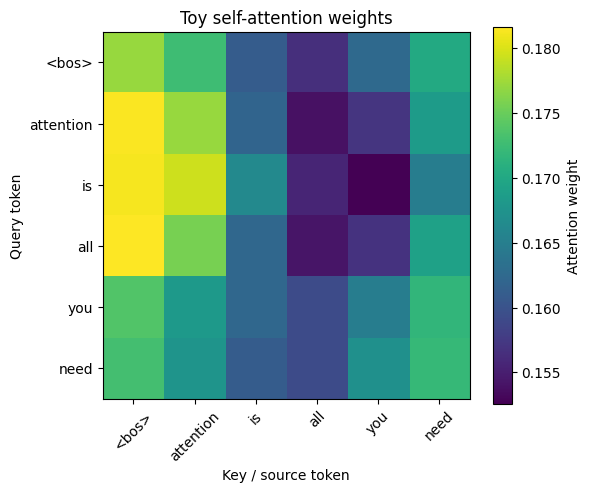

In [15]:
# Optional visualization only
try:
    import matplotlib.pyplot as plt
    plt.figure(figsize=(6, 5))
    plt.imshow(attn_weights, cmap="viridis")
    plt.colorbar(label="Attention weight")
    plt.xticks(range(len(tokens)), tokens, rotation=45)
    plt.yticks(range(len(tokens)), tokens)
    plt.xlabel("Key / source token")
    plt.ylabel("Query token")
    plt.title("Toy self-attention weights")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Install matplotlib only if you want the heatmap: pip install matplotlib")


## 12. Self-attention layer

Self-attention means Q, K, and V are all projected from the **same input sequence**. Every token can collect information from other tokens in that sequence.

The next function wraps the projections and attention operation into one layer. It returns the weights so you can inspect them.


In [16]:
class SelfAttentionLayer:
    def __init__(self, d_model):
        self.d_model = d_model
        self.WQ = random_matrix(d_model, d_model, 0.2)
        self.WK = random_matrix(d_model, d_model, 0.2)
        self.WV = random_matrix(d_model, d_model, 0.2)
        self.WO = random_matrix(d_model, d_model, 0.2)

    def forward(self, X, mask=None):
        Q = matmul(X, self.WQ)
        K = matmul(X, self.WK)
        V = matmul(X, self.WV)
        context, scores, weights = scaled_dot_product_attention(Q, K, V, mask)
        output = matmul(context, self.WO)
        return output, weights

self_attn = SelfAttentionLayer(d_model)
self_output, self_weights = self_attn.forward(X)
print_matrix("Self-attention layer output:", self_output)


Self-attention layer output:
[0.059, -0.106, 0.059, -0.072, 0.058, 0.092, 0.08, -0.015]
[0.059, -0.105, 0.058, -0.07, 0.058, 0.091, 0.081, -0.015]
[0.06, -0.104, 0.057, -0.069, 0.058, 0.09, 0.082, -0.015]
[0.059, -0.104, 0.058, -0.07, 0.058, 0.091, 0.081, -0.015]
[0.059, -0.106, 0.059, -0.072, 0.059, 0.092, 0.08, -0.015]
[0.059, -0.106, 0.059, -0.073, 0.059, 0.092, 0.08, -0.015]


## 13. Multi-head attention

For head \(i\):

\[
head_i=Attention(XW_i^Q,XW_i^K,XW_i^V)
\]

Then concatenate heads and project:

\[
MultiHead(X)=Concat(head_1,\ldots,head_h)W^O
\]

Each head has its own learned Q/K/V projections. We implement head splitting and concatenation explicitly. For simplicity, `d_model` must be divisible by the number of heads.


In [17]:
class MultiHeadAttention:
    def __init__(self, d_model, num_heads):
        assert d_model % num_heads == 0
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_head = d_model // num_heads
        self.WQ = random_matrix(d_model, d_model, 0.2)
        self.WK = random_matrix(d_model, d_model, 0.2)
        self.WV = random_matrix(d_model, d_model, 0.2)
        self.WO = random_matrix(d_model, d_model, 0.2)

    def split_heads(self, projected):
        # [sequence, d_model] -> list of [sequence, d_head] matrices
        heads = []
        for h in range(self.num_heads):
            start = h*self.d_head
            end = start+self.d_head
            heads.append([row[start:end] for row in projected])
        return heads

    def forward(self, X, mask=None):
        Q = self.split_heads(matmul(X, self.WQ))
        K = self.split_heads(matmul(X, self.WK))
        V = self.split_heads(matmul(X, self.WV))

        head_outputs, all_weights = [], []
        for h in range(self.num_heads):
            out, scores, weights = scaled_dot_product_attention(
                Q[h], K[h], V[h], mask
            )
            head_outputs.append(out)
            all_weights.append(weights)

        # Concatenate head outputs along the feature dimension.
        concatenated = []
        for pos in range(len(X)):
            row = []
            for h in range(self.num_heads):
                row.extend(head_outputs[h][pos])
            concatenated.append(row)

        final_output = matmul(concatenated, self.WO)
        return final_output, all_weights

mha = MultiHeadAttention(d_model=8, num_heads=2)
mha_output, mha_weights = mha.forward(X)
print_matrix("Multi-head output:", mha_output)
for i, w in enumerate(mha_weights):
    print_matrix(f"Head {i+1} weights:", w)


Multi-head output:
[0.029, 0.047, -0.069, -0.111, 0.002, 0.075, 0.079, -0.037]
[0.03, 0.047, -0.069, -0.111, 0.002, 0.076, 0.079, -0.037]
[0.03, 0.047, -0.07, -0.112, 0.003, 0.076, 0.079, -0.037]
[0.03, 0.047, -0.07, -0.112, 0.003, 0.076, 0.079, -0.037]
[0.03, 0.047, -0.07, -0.112, 0.003, 0.076, 0.079, -0.037]
[0.029, 0.047, -0.069, -0.112, 0.003, 0.076, 0.079, -0.037]
Head 1 weights:
[0.166, 0.166, 0.166, 0.169, 0.167, 0.166]
[0.166, 0.166, 0.164, 0.168, 0.168, 0.168]
[0.167, 0.164, 0.162, 0.166, 0.17, 0.171]
[0.164, 0.163, 0.165, 0.169, 0.171, 0.168]
[0.162, 0.163, 0.166, 0.172, 0.171, 0.166]
[0.163, 0.165, 0.168, 0.172, 0.168, 0.165]
Head 2 weights:
[0.167, 0.168, 0.168, 0.167, 0.165, 0.165]
[0.169, 0.167, 0.165, 0.165, 0.167, 0.168]
[0.173, 0.167, 0.159, 0.16, 0.169, 0.172]
[0.175, 0.167, 0.157, 0.157, 0.169, 0.174]
[0.175, 0.168, 0.16, 0.159, 0.167, 0.172]
[0.17, 0.168, 0.165, 0.164, 0.165, 0.168]


## 14. Masks: padding mask and causal/look-ahead mask

The paper's decoder uses a look-ahead (causal) mask so position \(i\) cannot attend to future positions \(j>i\). The encoder does not use this causal mask.

A causal mask for 4 positions:

\[
\begin{bmatrix}
0&1&1&1\\
0&0&1&1\\
0&0&0&1\\
0&0&0&0
\end{bmatrix}
\]

Here `1` means “block this attention link”. We add a very negative number to blocked scores before softmax, making their probabilities approximately zero.


In [18]:
def causal_mask(seq_len):
    return [[1 if j > i else 0 for j in range(seq_len)]
            for i in range(seq_len)]

cmask = causal_mask(4)
print_matrix("Causal mask (1 = blocked):", cmask)

# Verify future positions receive zero attention (approximately).
toy_Q = random_matrix(4, 3, 0.3)
toy_K = random_matrix(4, 3, 0.3)
toy_V = random_matrix(4, 3, 0.3)
causal_out, causal_scores, causal_weights = scaled_dot_product_attention(
    toy_Q, toy_K, toy_V, cmask
)
print_matrix("Causal attention weights:", causal_weights)


Causal mask (1 = blocked):
[0, 1, 1, 1]
[0, 0, 1, 1]
[0, 0, 0, 1]
[0, 0, 0, 0]
Causal attention weights:
[1.0, 0.0, 0.0, 0.0]
[0.496, 0.504, 0.0, 0.0]
[0.333, 0.324, 0.343, 0.0]
[0.248, 0.248, 0.252, 0.253]


### Padding mask

Padding tokens should not be used as keys. This mask is separate from the causal mask. We build a key-padding mask for a sequence where the final two positions are padding.


In [19]:
def key_padding_mask(valid_positions):
    # valid_positions: 1 for real token, 0 for PAD
    # Return [query_position][key_position] mask.
    n = len(valid_positions)
    return [[0 if valid_positions[j] == 1 else 1 for j in range(n)]
            for i in range(n)]

valid = [1, 1, 1, 0, 0]
pad_mask = key_padding_mask(valid)
print_matrix("Padding mask (1 = block key):", pad_mask)


Padding mask (1 = block key):
[0, 0, 0, 1, 1]
[0, 0, 0, 1, 1]
[0, 0, 0, 1, 1]
[0, 0, 0, 1, 1]
[0, 0, 0, 1, 1]


## 15. Position-wise Feed-Forward Network

The paper uses the same two-layer FFN independently at every position:

\[
FFN(x)=\max(0,xW_1+b_1)W_2+b_2
\]

The original paper uses **ReLU**. Later Transformer variants often use GELU or other activations. This implementation includes biases explicitly.


In [ ]:
class PositionwiseFFN:
    def __init__(self, d_model, d_ff):
        self.W1 = random_matrix(d_model, d_ff, 0.2)
        self.b1 = [0.0] * d_ff
        self.W2 = random_matrix(d_ff, d_model, 0.2)
        self.b2 = [0.0] * d_model

    def forward(self, X):
        hidden = matmul(X, self.W1)
        hidden = [[relu(v + b) for v, b in zip(row, self.b1)]
                  for row in hidden]
        output = matmul(hidden, self.W2)
        output = [[v + b for v, b in zip(row, self.b2)]
                  for row in output]
        return output

ffn = PositionwiseFFN(d_model=8, d_ff=32)
ffn_output = ffn.forward(X)
print_matrix("FFN output:", ffn_output)


## 16. Residual connections and Layer Normalization

The paper applies residual connection followed by LayerNorm:

\[
LayerNorm(x+sublayer(x))
\]

LayerNorm normalizes each token vector across its feature dimensions:

\[
\mu=\frac{1}{d}\sum_i x_i,\quad
\sigma^2=\frac{1}{d}\sum_i(x_i-\mu)^2
\]

\[
LN(x)_i=\gamma_i\frac{x_i-\mu}{\sqrt{\sigma^2+\epsilon}}+\beta_i
\]

We initialize \(\gamma=1,\beta=0\).


In [ ]:
def layer_norm_vector(x, gamma=None, beta=None, eps=1e-5):
    d = len(x)
    mean = sum(x)/d
    variance = sum((v-mean)**2 for v in x)/d
    if gamma is None: gamma = [1.0]*d
    if beta is None: beta = [0.0]*d
    return [gamma[i]*(x[i]-mean)/math.sqrt(variance+eps)+beta[i]
            for i in range(d)]

def layer_norm_matrix(X):
    return [layer_norm_vector(row) for row in X]

def residual_add_norm(x, sublayer_output):
    added = add_matrices(x, sublayer_output)
    return layer_norm_matrix(added)

normed = residual_add_norm(X, self_output)
print_matrix("LayerNorm(X + self-attention(X)):", normed)


## 17. Dropout

Dropout randomly sets a fraction \(p\) of activations to zero during training. The remaining activations are scaled by \(1/(1-p)\) (“inverted dropout”), so the expected activation remains unchanged.

At inference time, dropout is disabled.

\[
dropout(x_i)=\begin{cases}
0 & \text{with probability }p\\
x_i/(1-p) & \text{with probability }1-p
\end{cases}
\]

The paper used dropout with rate 0.1 in several places.


In [ ]:
def dropout_vector(x, p=0.1, training=True):
    if not training or p == 0:
        return x[:]
    result = []
    for value in x:
        if random.random() < p:
            result.append(0.0)
        else:
            result.append(value/(1.0-p))
    return result

sample = [1.0, 2.0, 3.0, 4.0, 5.0]
print("Training dropout:", dropout_vector(sample, p=0.4, training=True))
print("Inference (unchanged):", dropout_vector(sample, p=0.4, training=False))


## 18. Encoder layer: assemble the paper's encoder sublayers

One encoder layer contains:
1. Multi-head self-attention
2. Residual + LayerNorm
3. Position-wise FFN
4. Residual + LayerNorm

The paper stacks \(N=6\) identical encoder layers in the base configuration. Here we implement one small layer and then stack a few.


In [ ]:
class EncoderLayer:
    def __init__(self, d_model, num_heads, d_ff, dropout_p=0.1):
        self.mha = MultiHeadAttention(d_model, num_heads)
        self.ffn = PositionwiseFFN(d_model, d_ff)
        self.dropout_p = dropout_p

    def forward(self, X, training=True):
        attn, weights = self.mha.forward(X)
        attn = [dropout_vector(row, self.dropout_p, training) for row in attn]
        x = residual_add_norm(X, attn)

        ff = self.ffn.forward(x)
        ff = [dropout_vector(row, self.dropout_p, training) for row in ff]
        out = residual_add_norm(x, ff)
        return out, weights

encoder_layer = EncoderLayer(d_model=8, num_heads=2, d_ff=32)
encoder_out, encoder_attn = encoder_layer.forward(X, training=False)
print_matrix("One encoder layer output:", encoder_out)


## 19. Decoder layer: masked self-attention + cross-attention + FFN

The original Transformer decoder layer has three sublayers:

1. **Masked multi-head self-attention** over previously generated target tokens.
2. **Encoder–decoder attention (cross-attention):** decoder states form Q; encoder outputs provide K and V.
3. **Position-wise FFN.**

Each sublayer has a residual connection and LayerNorm.

The key cross-attention equation is:

\[
Q=Y W^Q,\quad K=Z W^K,\quad V=Z W^V
\]

where \(Y\) is the decoder-side representation and \(Z\) is the encoder output.


In [ ]:
class DecoderLayer:
    def __init__(self, d_model, num_heads, d_ff, dropout_p=0.1):
        self.masked_mha = MultiHeadAttention(d_model, num_heads)
        self.cross_WQ = random_matrix(d_model, d_model, 0.2)
        self.cross_WK = random_matrix(d_model, d_model, 0.2)
        self.cross_WV = random_matrix(d_model, d_model, 0.2)
        self.cross_WO = random_matrix(d_model, d_model, 0.2)
        self.ffn = PositionwiseFFN(d_model, d_ff)
        self.dropout_p = dropout_p

    def cross_attention(self, Y, encoder_states):
        Q = matmul(Y, self.cross_WQ)                 # decoder queries
        K = matmul(encoder_states, self.cross_WK)    # encoder keys
        V = matmul(encoder_states, self.cross_WV)    # encoder values
        context, scores, weights = scaled_dot_product_attention(Q, K, V)
        return matmul(context, self.cross_WO), weights

    def forward(self, Y, encoder_states, training=True):
        # 1) Masked decoder self-attention
        mask = causal_mask(len(Y))
        self_out, self_weights = self.masked_mha.forward(Y, mask)
        self_out = [dropout_vector(row, self.dropout_p, training) for row in self_out]
        y = residual_add_norm(Y, self_out)

        # 2) Encoder-decoder cross-attention
        cross_out, cross_weights = self.cross_attention(y, encoder_states)
        cross_out = [dropout_vector(row, self.dropout_p, training) for row in cross_out]
        y = residual_add_norm(y, cross_out)

        # 3) Feed-forward
        ff = self.ffn.forward(y)
        ff = [dropout_vector(row, self.dropout_p, training) for row in ff]
        y = residual_add_norm(y, ff)

        return y, self_weights, cross_weights

decoder_layer = DecoderLayer(d_model=8, num_heads=2, d_ff=32)
# Toy target-side vectors; use a few rows from X for shape-compatible demo.
Y = X[:3]
decoder_out, dec_self_weights, cross_weights = decoder_layer.forward(
    Y, encoder_out, training=False
)
print_matrix("Decoder output:", decoder_out)
print_matrix("Decoder masked self-attention head 1:", dec_self_weights[0])
print_matrix("Decoder cross-attention weights:", cross_weights)


## 20. Linear projection, softmax and label smoothing

The decoder output is projected to vocabulary logits:

\[
logits = hW_{vocab}+b
\]

Softmax converts logits into probabilities.

**Label smoothing** replaces a hard one-hot target with a softened target distribution. The paper used \(\epsilon_{ls}=0.1\). One common form is:

\[
q_k=(1-\epsilon)\mathbf{1}[k=y]+\frac{\epsilon}{V}
\]

and cross-entropy:

\[
L=-\sum_k q_k\log p_k
\]

Some implementations distribute smoothing mass only over non-target classes; this notebook uses the simple uniform-over-all-classes convention above and states it explicitly.


In [ ]:
def linear_projection(X, W, b):
    logits = matmul(X, W)
    return [[v + bias for v, bias in zip(row, b)] for row in logits]

def cross_entropy_with_label_smoothing(logits, target_id, epsilon=0.1):
    probs = softmax(logits)
    vocab_size = len(logits)
    target_dist = [epsilon/vocab_size for _ in range(vocab_size)]
    target_dist[target_id] += (1.0-epsilon)
    loss = -sum(q*math.log(max(p, 1e-12))
                for q, p in zip(target_dist, probs))
    return loss, probs, target_dist

toy_vocab_size = 6
W_vocab = random_matrix(d_model, toy_vocab_size, 0.2)
b_vocab = [0.0]*toy_vocab_size
toy_logits = linear_projection(decoder_out, W_vocab, b_vocab)

target_token_id = 2
loss, probs, smoothed_target = cross_entropy_with_label_smoothing(
    toy_logits[0], target_token_id, epsilon=0.1
)
print("Logits:", [round(x,3) for x in toy_logits[0]])
print("Probabilities:", [round(x,3) for x in probs])
print("Smoothed target:", [round(x,3) for x in smoothed_target])
print("Label-smoothed loss:", round(loss,4))


## 21. Tiny end-to-end Transformer forward pass

This assembles the main paper structure:
- source token embeddings + positional encodings
- stacked encoder layers
- target token embeddings + positional encodings
- stacked decoder layers
- linear vocabulary projection + softmax

All weights are random, so the generated token predictions are meaningless until the model is trained. This cell is about connecting the shapes and data flow.


In [ ]:
# Tiny source and target vocabularies
source_tokens = ["<pad>", "<bos>", "<eos>", "I", "like", "cats"]
target_tokens = ["<pad>", "<bos>", "<eos>", "J'aime", "les", "chats"]

src_vocab = {t:i for i,t in enumerate(source_tokens)}
tgt_vocab = {t:i for i,t in enumerate(target_tokens)}

def embed_sequence(ids, table):
    return [table[i][:] for i in ids]

def add_position(vectors):
    pe = sinusoidal_position_encoding(len(vectors), len(vectors[0]))
    return add_matrices(vectors, pe)

D_MODEL = 8
src_E = random_matrix(len(source_tokens), D_MODEL, 0.2)
tgt_E = random_matrix(len(target_tokens), D_MODEL, 0.2)

src_ids = [src_vocab[t] for t in ["<bos>", "I", "like", "cats", "<eos>"]]
tgt_input_ids = [tgt_vocab[t] for t in ["<bos>", "J'aime", "les"]]

src_x = add_position(embed_sequence(src_ids, src_E))
tgt_x = add_position(embed_sequence(tgt_input_ids, tgt_E))

# Stack two tiny encoder layers
enc_layers = [EncoderLayer(D_MODEL, 2, 32) for _ in range(2)]
memory = src_x
for layer in enc_layers:
    memory, _ = layer.forward(memory, training=False)

# Stack two tiny decoder layers
dec_layers = [DecoderLayer(D_MODEL, 2, 32) for _ in range(2)]
decoded = tgt_x
for layer in dec_layers:
    decoded, _, _ = layer.forward(decoded, memory, training=False)

# Project each decoder position to target vocabulary logits
W_out = random_matrix(D_MODEL, len(target_tokens), 0.2)
b_out = [0.0]*len(target_tokens)
logits = linear_projection(decoded, W_out, b_out)
probabilities = [softmax(row) for row in logits]

print("Encoder memory shape:", len(memory), "x", len(memory[0]))
print("Decoder states shape:", len(decoded), "x", len(decoded[0]))
print("Output distribution at final supplied target position:")
for token, p in zip(target_tokens, probabilities[-1]):
    print(token, round(p, 4))


## 22. Greedy autoregressive decoding (conceptual)

At inference, the decoder is given `<bos>`, predicts the next token, appends it, and repeats until `<eos>` or a maximum length. The following function demonstrates the **control flow** using a supplied toy prediction function. It is not a trained Transformer decoder.


In [ ]:
def greedy_decode_demo(start_token, eos_token, predict_next_id, max_steps=10):
    generated = [start_token]
    for _ in range(max_steps):
        next_id = predict_next_id(generated)
        generated.append(next_id)
        if next_id == eos_token:
            break
    return generated

# Deterministic mock predictor to demonstrate the loop only.
mock_sequence = [3, 4, 5, 2]  # J'aime, les, chats, EOS
def mock_predict(prefix):
    return mock_sequence[len(prefix)-1]

print("Greedy decoding demo:", greedy_decode_demo(
    start_token=1, eos_token=2, predict_next_id=mock_predict
))


## 23. What is in the paper, and what is background?

| Concept | In *Attention Is All You Need*? | Why it appears here |
|---|---|---|
| BPE | Yes, tokenization choice | Paper's subword tokenization |
| One-hot encoding | Not a model layer | Explains sparse token representation |
| Learned embeddings | Yes | Input/output token embeddings |
| Word2Vec / CBOW / Skip-gram | No | Earlier learned word representation methods |
| Latent representations | General concept | Explains learned vectors |
| RNN / LSTM | No; Transformer replaces recurrence | Historical comparison |
| Q/K/V | Yes | Attention projections |
| Scaled \(QK^T V\) attention | Yes, with row-wise softmax between scores and V | Core attention formula |
| Positional encoding | Yes | Sinusoidal in the original paper |
| Self-attention | Yes | Encoder and decoder sublayers |
| Feed-forward network | Yes | Position-wise two-layer FFN with ReLU |
| Decoder | Yes | Masked self-attention + cross-attention + FFN |
| LayerNorm + residual | Yes | Post-norm in original paper |
| Masking | Yes | Decoder look-ahead mask |
| Multi-head attention | Yes | Multiple parallel attention heads |
| Dropout | Yes | Regularization, paper uses 0.1 |
| Label smoothing | Yes | Paper uses 0.1 |

## 24. Suggested experiments

1. **Attention:** Change Q and K so one query has a much larger dot product with one key. Watch softmax concentrate.
2. **Scaling:** Remove division by \(\sqrt{d_k}\) and compare the softmax distributions.
3. **Heads:** Change `num_heads` from 2 to 4 while keeping `d_model` divisible by it.
4. **Positional encoding:** Print PE for positions 0–5. Notice even dimensions use sine and odd dimensions use cosine.
5. **Causal mask:** Confirm every row has zero attention weight on future positions.
6. **Dropout:** Run repeatedly with `training=True`; compare with `training=False`.
7. **Label smoothing:** Compare loss with epsilon 0 and 0.1.
8. **BPE:** Train on a corpus with repeated prefixes/suffixes and inspect the merge sequence.

## 25. The most important paper equations — quick reference

**Scaled dot-product attention**

\[
Attention(Q,K,V)=softmax\left(\frac{QK^T}{\sqrt{d_k}}\right)V
\]

**Multi-head attention**

\[
MultiHead(Q,K,V)=Concat(head_1,\ldots,head_h)W^O
\]

**Position-wise FFN**

\[
FFN(x)=max(0,xW_1+b_1)W_2+b_2
\]

**Sinusoidal positional encoding**

\[
PE(pos,2i)=\sin\left(pos/10000^{2i/d_{model}}\right)
\]

\[
PE(pos,2i+1)=\cos\left(pos/10000^{2i/d_{model}}\right)
\]

**Residual + normalization (post-norm)**

\[
LayerNorm(x+Sublayer(x))
\]

**Label-smoothed cross-entropy**

\[
L=-\sum_k q_k\log p_k
\]

---

### Final learning challenge

Once you have run the notebook, try to answer without looking at the code:

1. Why does the encoder use self-attention without a causal mask?
2. Why does the decoder use both masked self-attention and encoder–decoder attention?
3. Why divide \(QK^T\) by \(\sqrt{d_k}\)?
4. Why concatenate multiple heads instead of averaging them?
5. Why add positional encoding to token embeddings?
6. Why does the original paper use residual connections followed by LayerNorm?
7. Why does label smoothing discourage the model from becoming overconfident?

If you can explain these and reproduce the code, you will have a strong mathematical and implementation-level understanding of the original Transformer architecture.
